# 1D Diffusion Equation: Explicit FTCS Scheme

## 1. Theory & Stability Analysis
The 1D diffusion equation is:
$$\frac{\partial \rho}{\partial t} = D \frac{\partial^2 \rho}{\partial x^2}$$

Using Forward Time Centered Space (FTCS) discretization:
$$\rho_i^{n+1} = \rho_i^n + C (\rho_{i+1}^n + \rho_{i-1}^n - 2\rho_i^n), \quad C = \frac{D \Delta t}{\Delta x^2}$$

**von Neumann Stability Condition:**
$$C = \frac{D \Delta t}{\Delta x^2} \le \frac{1}{2} \implies \Delta t \le \frac{\Delta x^2}{2D}$$

**Decay of Fourier Modes:**
$$\hat{\rho}(k, t) = \hat{\rho}(k, 0) e^{-D k^2 t}, \quad \tau_k = \frac{1}{D k^2} = \frac{\lambda^2}{4\pi^2 D}$$
Modes with shorter wavelength $\lambda$ (higher wavenumber $k$) equilibrate quadratically faster.

## 2. EXACT CODE FROM QUIZ 2 REFERENCE PDF (Section 2.1)
1D Diffusion with FTCS explicit scheme, Neumann no-flux boundary condition, and total particle conservation check.

Diffusion Courant number C = 0.2222 (Must be <= 0.5 for stability)


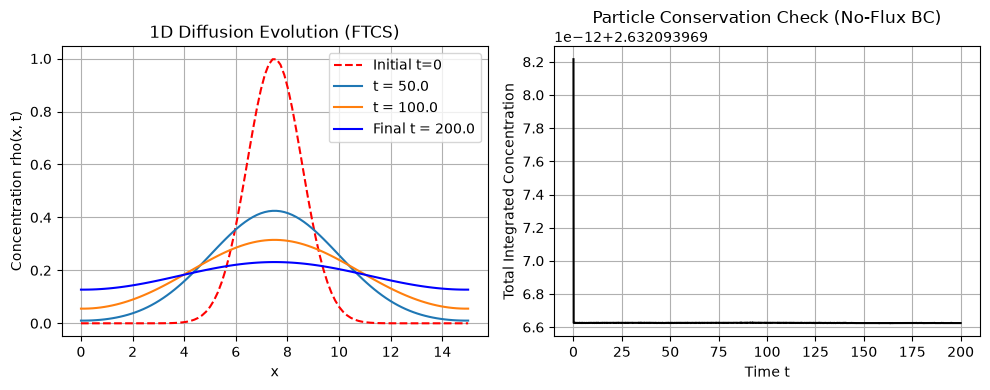

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
N = 100               # Number of grid points
dx = 0.15             # Spatial resolution
L = N * dx            # System size
D = 0.05              # Diffusion coefficient
dt = 0.1              # Temporal step (Check stability: D*dt/dx^2 = 0.222 <= 0.5)
t_end = 200.0         # Final simulation time

# Stability verification
C = D * dt / (dx**2)
print(f"Diffusion Courant number C = {C:.4f} (Must be <= 0.5 for stability)")
assert C <= 0.5, "Stability condition violated: D*dt/dx^2 > 0.5!"

# Spatial and temporal vectors
x = np.linspace(0, L, N)
t = np.arange(0, t_end + dt, dt)

# Initial condition: centered Gaussian concentration pulse
rho_0 = np.exp(-((x - L/2) / 1.5)**2)
rho = rho_0.copy()
rho_temp = np.zeros(N)

# Storage for space-time evolution and particle conservation
rho_history = [rho.copy()]
total_particles = [np.sum(rho[1:-1]) * dx]

# FTCS Time Stepping
for n in range(1, len(t)):
    # Interior update using FTCS
    for i in range(1, N - 1):
        rho_temp[i] = rho[i] + C * (rho[i+1] + rho[i-1] - 2 * rho[i])
        
    # Boundary Conditions (Choose one):
    # (A) Neumann (No-Flux): rho[0] = rho[1], rho[-1] = rho[-2]
    rho_temp[0] = rho_temp[1]
    rho_temp[-1] = rho_temp[-2]
    
    # (B) Dirichlet: Uncomment for fixed boundary values
    # rho_temp[0] = 1.0; rho_temp[-1] = 0.0

    rho = rho_temp.copy()
    rho_history.append(rho.copy())
    total_particles.append(np.sum(rho[1:-1]) * dx)

# Plotting
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(x, rho_0, 'r--', label='Initial t=0')
plt.plot(x, rho_history[len(t)//4], label=f't = {t[len(t)//4]:.1f}')
plt.plot(x, rho_history[len(t)//2], label=f't = {t[len(t)//2]:.1f}')
plt.plot(x, rho, 'b-', label=f'Final t = {t_end:.1f}')
plt.xlabel('x')
plt.ylabel('Concentration rho(x, t)')
plt.title('1D Diffusion Evolution (FTCS)')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(t, total_particles, 'k-')
plt.xlabel('Time t')
plt.ylabel('Total Integrated Concentration')
plt.title('Particle Conservation Check (No-Flux BC)')
plt.grid(True)
plt.tight_layout()
plt.show()

## 3. EXACT CODE FROM QUIZ 2 REFERENCE PDF (Section 2.2)
Fourier mode decay verification: numerical amplitude decay vs. exact analytical exponential $\exp(-D k^2 t)$.

In [19]:
import numpy as np
import matplotlib.pyplot as plt

L = 2.0 * np.pi
N = 200
dx = L / N
x = np.linspace(0, L, N, endpoint=False)
D = 0.1
dt = 0.001
C = D * dt / (dx**2)
assert C <= 0.5

# Two initial modes: low wavenumber k1=1, high wavenumber k2=4
k1, k2 = 1.0, 4.0
rho1 = np.sin(k1 * x)
rho2 = np.sin(k2 * x)

# Analytical decay rates: exp(-D * k^2 * t)
t_target = 0.5
nt = int(t_target / dt)

for n in range(nt):
    rho1_new = rho1 + C * (np.roll(rho1, -1) + np.roll(rho1, 1) - 2 * rho1)
    rho2_new = rho2 + C * (np.roll(rho2, -1) + np.roll(rho2, 1) - 2 * rho2)
    rho1, rho2 = rho1_new, rho2_new

print(f"Mode k=1 amplitude ratio numerical: {np.max(rho1):.4f}, exact: {np.exp(-D*k1**2*t_target):.4f}")
print(f"Mode k=4 amplitude ratio numerical: {np.max(rho2):.4f}, exact: {np.exp(-D*k2**2*t_target):.4f}")
print(f"Theoretical decay rate ratio: (k2/k1)^2 = {(k2/k1)**2:.1f}x faster")


Mode k=1 amplitude ratio numerical: 0.9512, exact: 0.9512
Mode k=4 amplitude ratio numerical: 0.4486, exact: 0.4493
Theoretical decay rate ratio: (k2/k1)^2 = 16.0x faster


## 4. PROFESSOR'S IN-CLASS CODE (from `Notes/1D_diffusion.ipynb`)
This is the code as directly written in the professor's in-class notebook with Dirichlet BC (`rho[0]=1, rho[-1]=0`) and total particle sum tracking.

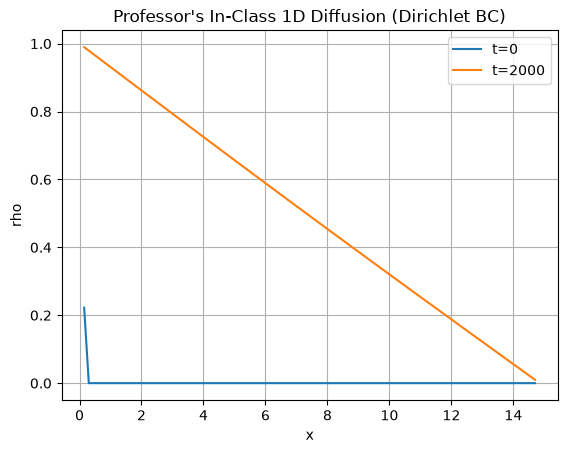

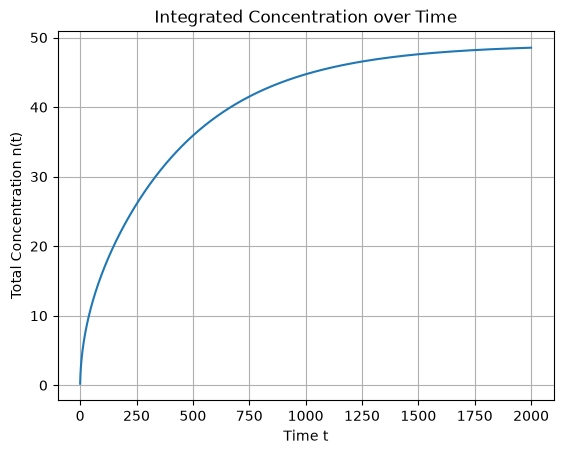

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
N = 100          # Total number of grid points
dt = 0.1         # Temporal step size
dx = 0.15        # Spatial step size
D = 0.05         # Diffusion constant
L = N * dx       # System size
t_end = 2000      # Final time

# Initialize arrays
rho = np.zeros(N)       # Concentration field 
rho_0 = np.zeros(N)     # Initial concentration field
rho_temp = np.zeros(N)  # temporary concentration-field vector 

# Spatial and temporal vectors
x = np.arange(0, L, dx) # site vector
t = np.arange(dt, t_end, dt) # time vector

# Initial condition
#rho_0 = np.exp(-((x - L/2)/5)**2)

# Initialize concentration field
rho = rho_0.copy()

rho_T = np.zeros((N, len(t))) # Array to store concentration at different time points
n = np.zeros(len(t)) # Total no. of particles

for i in range(len(t)):

    '''
    # No-flux (Neumann) boundary conditions
    rho[-1] = rho[-2]
    rho[0] = rho[1]
    '''
    
    # Dirichlet boundary conditions
    rho[0]=1
    rho[-1]=0
    

    # Update concentration at interior grid points
    for p in range(1, N-1):

        rho_temp[p] = (rho[p] + D * dt / (dx * dx) *(rho[p+1] + rho[p-1] - 2*rho[p]))
        
    # Update concentration field
    rho = rho_temp.copy() # use .copy() to create separate memory space for rho and rho_temp
    #rho[1:N-2]=rho_temp[1:N-2]

    # Store concentration profile
    rho_T[:, i] = rho

    # Total concentration
    n[i] = np.sum(rho[1:-1])

plt.plot(x[1:-1], rho_T[1:-1, 0], label='t=0')
plt.plot(x[1:-1], rho_T[1:-1, len(t)-1], label=f't={t_end}')
plt.xlabel('x')
plt.ylabel('rho')
plt.title('Professor\'s In-Class 1D Diffusion (Dirichlet BC)')
plt.legend()
plt.grid(True)
plt.show()

plt.figure()
plt.plot(t, n)
plt.xlabel('Time t')
plt.ylabel('Total Concentration n(t)')
plt.title('Integrated Concentration over Time')
plt.grid(True)
plt.show()